The goal of the part a is to design the wall contour for a CD nozzle to allow shock-free isentropic expansion of a gas. 

Approach :   
1. Two sections : Expansion section - Straightening section  
2. When the point lies at the centerline, K+ and K- are same and opposite similar to the shock tube problem. thus, theta = 0 and nu can be directly calculated. 
3. Every characteristic lines hitting the wall 12 and 13 are completely straight lines and ends at points on the wall of the straightening section  

In [13]:
import numpy as np 
from scipy.optimize import brentq
import matplotlib.pyplot as plt

# HW PARAMETERS
gamma = 1.4
M_exit = 3

#Nozzle geometry
R_t = 1 # Is the throat square? Ask at the office hours
x_throat = 0
y_centerline = 0

n = 4                          # number of rays

HW4 functions

In [14]:
#Takes in m and gamma to return nu_m, deflection angle in radian
def PrandtlMeyer (m, gamma):
    M = m **2
    nu_m = np.sqrt(((gamma+1)/(gamma-1))) * np.atan(np.sqrt(((gamma-1)/(gamma+1))*(M-1))) - np.atan(np.sqrt(M-1))
    return nu_m
 
#Brentq is part of the Scipy otpimization package, that utilizes Brents method to find the solution to m from nu_m
def InversePrandtlMeyer (nu_m, gamma):
    m = brentq(lambda m: PrandtlMeyer(m, gamma) - nu_m, 1, 1e6)
    return m

Helper functions; self explanatory

In [15]:
#Find mu(mach angle)
def mu(M):
    return np.arcsin(1/M)

#Returns the intersection point of two functions, defined by 
# y_b = m-b(x_b) + b_a
# y_a = m_a(x_a) + b_b
def intersection(x_a, y_a, m_a, x_b, y_b, m_b):
    # lines in the form y = m*x + b
    b_a = y_a - m_a*x_a
    b_b = y_b - m_b*x_b
    x = (b_b - b_a)/(m_a - m_b)
    y = m_a*x + b_a
    return x, y

In [16]:
# point (THIS IS THE U AND P) = [theta, nu, M, mu, J_minus, J_plus, x, y]
# rows[i] = [axis point, internal points ..., wall point]
# lines   = [x_a, y_a, x_b, y_b, color, linewidth, label], drawn in this order

theta_max = PrandtlMeyer(M_exit, gamma)/2
dt = int(theta_max)/(n - 1)

# From HW6 
def state_from_invariants(J_minus, J_plus):
    theta = 0.5*(J_minus + J_plus)
    nu = 0.5*(J_minus - J_plus)
    M = InversePrandtlMeyer(nu, gamma)
    return theta, nu, M, mu(M)


# sign = -1 for J-, +1 for J+
def characteristic_slope(theta_1, mu_1, theta_2, mu_2, sign):
    return np.tan(0.5*(theta_1 + theta_2) + sign*0.5*(mu_1 + mu_2))


#Upstream function constructs the i=0 cases
#Otherwise, the parent is one before. 
#i goes from 0 to n
#J is subloop of i, so it returns J - (i+1)

#Three possible cases 

# centerline point = j = i (end of each j loop)
# Internal point = anywhere in between 
# wall point = j = n(end of each i loop)
def upstream(i, j, rows):
    if i == 0:
        theta = delta_theta + min(j, n - 1)*dt         # ray n-1 has theta = theta_max, the wall's initial angle
        nu = PrandtlMeyer(1, gamma) + theta
        M = InversePrandtlMeyer(nu, gamma)
        return [theta, nu, M, mu(M), theta + nu, None, x_throat, R_t]
    return rows[i - 1][j - i + 1]

In [ ]:

# point data structure (THIS IS THE U AND P) = [theta, nu, M, mu, J_minus, J_plus, x, y]

def centerline_point(Upstream):
    # ray meets the centreline (theta = 0)
    theta_u, _, _, mu_u, J_minus, _, x_u, y_u = Upstream

    #Centerline, same as the HW6 
    J_plus = -J_minus

    theta, nu, M, mu = state_from_invariants(J_minus, J_plus)
    x = x_u - y_u/characteristic_slope(theta_u, mu_u, theta, mu, -1)
    return [theta, nu, M, mu, J_minus, J_plus, x, y_centerline]


def internal_point(Upstream, Previous):
    # C- from the upstream point U meets C+ from the previous point P in the row
    theta_u, _, _, mu_u, J_minus, _, x_u, y_u = Upstream
    theta_p, _, _, mu_p, _, J_plus, x_p, y_p = Previous
    theta, nu, M, mu = state_from_invariants(J_minus, J_plus)
    m_minus = characteristic_slope(theta_u, mu_u, theta, mu, -1)
    m_plus = characteristic_slope(theta_p, mu_p, theta, mu, +1)
    x, y = intersection(x_p, y_p, m_plus, x_u, y_u, m_minus)
    return [theta, nu, M, mu, J_minus, J_plus, x, y]


def wall_point(Upstream, Previous):
    # C+ from the previous point P meets the wall segment from the upstream wall point U
    theta_u, _, _, _, _, _, x_u, y_u = Upstream
    theta_p, _, _, mu_p, _, _, x_p, y_p = Previous
    m_wall = np.tan(0.5*(theta_u + theta_p))
    m_plus = np.tan(theta_p + mu_p)
    x, y = intersection(x_p, y_p, m_plus, x_u, y_u, m_wall)
    return Previous[:6] + [x, y]


In [20]:
# point = [theta, nu, M, mu, J_minus, J_plus, x, y]
# rows[i] = [axis point, internal points ..., wall point]

theta_max = PrandtlMeyer(M_exit, gamma)/2
theta_max_deg = np.rad2deg(theta_max)
delta_theta = np.deg2rad(theta_max_deg - int(theta_max_deg))
dt = np.deg2rad(int(theta_max_deg)/(n - 1))


rows = []
for i in range(n):
    row = []
    for j in range(i, n + 1):
        U = upstream(i, j, rows)
        if j == i:
            row.append(centerline_point(U))
        elif j < n:
            row.append(internal_point(U, row[-1]))
        else:
            row.append(wall_point(U, row[-1]))
    rows.append(row)
    print("Axis Points: ", *row[0][6:8])
    print("Wall points: ", *row[-1][6:8], "\n")


Axis Points:  0.45847088987068657 0
Wall points:  1.712744622228419 1.7783537175986024 

Axis Points:  1.3511185712861593 0
Wall points:  4.5780295592521725 2.821232147366559 

Axis Points:  2.516313871958184 0
Wall points:  8.971803505690644 3.755157630176845 

Axis Points:  4.912575021225119 0
Wall points:  17.151585694461193 4.327143721029879 



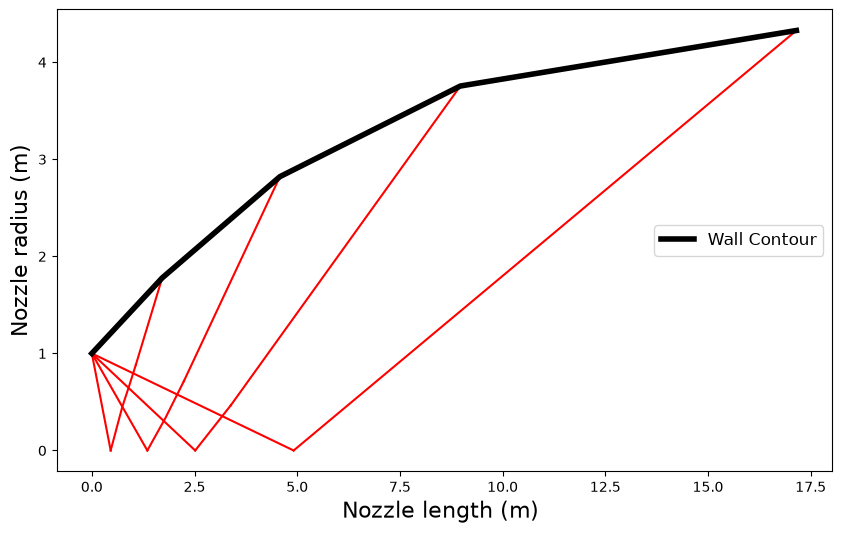

In [21]:
plt.figure(figsize=(10, 6))
for row in rows:
    x = [p[6] for p in row]
    y = [p[7] for p in row]
    plt.plot([x[0], x_throat], [y[0], R_t], color = 'red')
    plt.plot(x[:-1], y[:-1], color = 'red')
    plt.plot(x[-2:], y[-2:], color = 'red')

wall_x = [x_throat] + [row[-1][6] for row in rows]
wall_y = [R_t] + [row[-1][7] for row in rows]
plt.plot(wall_x, wall_y, color='black', linewidth=4, label='Wall Contour')

plt.xlabel("Nozzle length (m) ", fontsize=16)
plt.ylabel("Nozzle radius (m)", fontsize=16)
plt.legend(loc=7, prop={'size': 12})
plt.show()

I looked at more than 2 codebase to understand how the 2D MOC nozzle works. 
No AI was used. All functions were written by me. 

https://github.com/nategphillips/moc/tree/main
https://github.com/ekremekc/MoC
